In [1]:
import pandas as pd

In [2]:
#load SGJobData.csv into the data folder
df = pd.read_csv('SGJobData.csv')


In [4]:
df.shape                    # 1. How big is your sample? (rows, columns)
df.info()                   # 2. What columns do you have, and what types are they?
df.describe()     # 3. Pick one numeric column — what's typical, what's extreme?


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048585 entries, 0 to 1048584
Data columns (total 22 columns):
 #   Column                              Non-Null Count    Dtype  
---  ------                              --------------    -----  
 0   categories                          1044597 non-null  object 
 1   employmentTypes                     1044597 non-null  object 
 2   metadata_expiryDate                 1044597 non-null  object 
 3   metadata_isPostedOnBehalf           1048585 non-null  bool   
 4   metadata_jobPostId                  1044597 non-null  object 
 5   metadata_newPostingDate             1044597 non-null  object 
 6   metadata_originalPostingDate        1044597 non-null  object 
 7   metadata_repostCount                1048585 non-null  int64  
 8   metadata_totalNumberJobApplication  1048585 non-null  int64  
 9   metadata_totalNumberOfView          1048585 non-null  int64  
 10  minimumYearsExperience              1048585 non-null  int64  
 11  numberOfVac

,metadata_repostCount,metadata_totalNumberJobApplication,metadata_totalNumberOfView,minimumYearsExperience,numberOfVacancies,occupationId,salary_maximum,salary_minimum,status_id,average_salary
count,1.048585e+06,1.048585e+06,1.048585e+06,1.048585e+06,1.048585e+06,0.0,1.048585e+06,1.048585e+06,1048585.0,1.048585e+06
mean,5.472327e-02,2.136571e+00,2.674536e+01,2.779573e+00,2.680043e+00,NaN,5.723578e+03,3.815312e+03,0.0,4.769445e+03
std,2.822675e-01,1.062612e+01,8.262001e+01,2.537049e+00,1.124301e+01,NaN,5.018387e+04,3.172182e+03,0.0,2.547809e+04
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN,0.000000e+00,0.000000e+00,0.0,0.000000e+00
25%,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,NaN,3.300000e+03,2.500000e+03,0.0,2.900000e+03
50%,0.000000e+00,0.000000e+00,4.000000e+00,2.000000e+00,1.000000e+00,NaN,4.500000e+03,3.000000e+03,0.0,3.800000e+03
75%,0.000000e+00,1.000000e+00,1.700000e+01,4.000000e+00,2.000000e+00,NaN,6.500000e+03,4.500000e+03,0.0,5.500000e+03
max,2.000000e+00,1.342000e+03,8.190000e+03,8.800000e+01,9.990000e+02,NaN,2.533000e+07,3.500000e+05,0.0,1.266640e+07


In [5]:
df.isna().sum()

categories                               3988
employmentTypes                          3988
metadata_expiryDate                      3988
metadata_isPostedOnBehalf                   0
metadata_jobPostId                       3988
metadata_newPostingDate                  3988
metadata_originalPostingDate             3988
metadata_repostCount                        0
metadata_totalNumberJobApplication          0
metadata_totalNumberOfView                  0
minimumYearsExperience                      0
numberOfVacancies                           0
occupationId                          1048585
positionLevels                           3988
postedCompany_name                       3988
salary_maximum                              0
salary_minimum                              0
salary_type                              3988
status_id                                   0
status_jobStatus                         3988
title                                    3988
average_salary                    

In [6]:
key_columns = [
    "categories",
    "employmentTypes",
    "metadata_jobPostId",
    "positionLevels",
    "postedCompany_name",
    "salary_type",
    "title"
]
df[key_columns].isna().all(axis=1).sum()

3988

In [ ]:
df = df.dropna(subset=key_columns, how='all')


(1044597, 22)

In [ ]:
df = df.drop(columns=["occupationId"])
df.shape

In [9]:
columns_to_check = [
    "employmentTypes",
    "positionLevels",
    "salary_type",
]

for col in columns_to_check:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts())


Value counts for employmentTypes:
Permanent                458139
Full Time                393352
Contract                 139182
Part Time                 25431
Temporary                 18241
Internship/Attachment      6959
Freelance                  2139
Flexi-work                 1154
Name: employmentTypes, dtype: int64

Value counts for positionLevels:
Executive            253701
Junior Executive     167656
Non-executive        131608
Fresh/entry level    118661
Professional         112208
Manager              110122
Senior Executive     100459
Middle Management     27375
Senior Management     22807
Name: positionLevels, dtype: int64

Value counts for salary_type:
Monthly    1044597
Name: salary_type, dtype: int64


### Exploring the Salary Columns

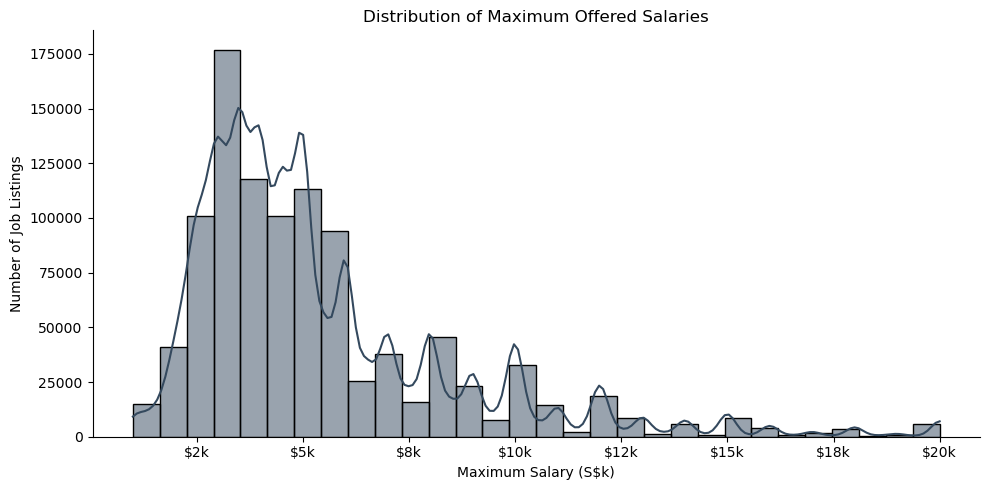

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns 
from matplotlib.ticker import FuncFormatter

# 1\. Create figure and axis 
fig, ax = plt.subplots(figsize=(10, 5)) 
# 2\. Plot distribution 
sns.histplot(
    data=df, 
    x="salary_maximum", 
    kde=True, 
    bins=30,
    color="#34495e",
    ax=ax
)

ax.set_title("Distribution of Maximum Offered Salaries") 
ax.set_xlabel("Maximum Salary (S$k)")
ax.set_ylabel("Number of Job Listings") # Format X-axis ticks into thousands ($k) 
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1000:.0f}k")) 
# Remove top and right borders for a clean look 
ax.spines[["top", "right"]].set_visible(False) 
plt.tight_layout() 
plt.show()


In [22]:
salary_df = df[
    ["title", "salary_minimum", "salary_maximum", "average_salary","positionLevels","employmentTypes"]
].copy()

salary_df = salary_df.sort_values(
    by="salary_maximum",
    ascending=True
)

salary_df.head(5)

,title,salary_minimum,salary_maximum,average_salary,positionLevels,employmentTypes
718635,Senior Design Engineer(Stand in),1,1,1.0,Manager,Temporary
120014,China Correspondent,1,1,1.0,Manager,Full Time
754822,Resident Engineer (Stand in),1,1,1.0,Manager,Temporary
754832,Workshop Manager,1,1,1.0,Manager,Full Time
133683,cleaner,1,1,1.0,Non-executive,Contract


In [23]:
salary_df.describe()

,salary_minimum,salary_maximum,average_salary
count,1.044597e+06,1.044597e+06,1.044597e+06
mean,3.829878e+03,5.745429e+03,4.787654e+03
std,3.169443e+03,5.027833e+04,2.552497e+04
min,1.000000e+00,1.000000e+00,1.000000e+00
25%,2.500000e+03,3.300000e+03,2.900000e+03
50%,3.000000e+03,4.500000e+03,3.800000e+03
75%,4.500000e+03,6.500000e+03,5.500000e+03
max,3.500000e+05,2.533000e+07,1.266640e+07


In [24]:
salary_df['salary_range'] = salary_df['salary_maximum'] - salary_df['salary_minimum']

salary_df = salary_df.sort_values(
    by="salary_range",
    ascending=True
)

salary_df.head(5)


,title,salary_minimum,salary_maximum,average_salary,positionLevels,employmentTypes,salary_range
718635,Senior Design Engineer(Stand in),1,1,1.0,Manager,Temporary,0
897400,"Pastry Chef (up to $2,700 | Mon to Fri, 5 days...",2700,2700,2700.0,Non-executive,Permanent,0
296402,Warehouse Assistant | Kallang | 5 DAYS | From ...,1900,1900,1900.0,Fresh/entry level,Contract,0
897456,Security Officers in Office at Raffles Place O...,2700,2700,2700.0,Junior Executive,Full Time,0
693162,Junior Sales Coordinator | Training Provided |...,1900,1900,1900.0,Junior Executive,Permanent,0


In [25]:
#looking at the columns in salary minimum and maximum to see if there are any outliers
salary_df[[
    "salary_minimum",
    "salary_maximum",
    "average_salary"
]].describe(percentiles=[0.05, 0.10, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99])

,salary_minimum,salary_maximum,average_salary
count,1.044597e+06,1.044597e+06,1.044597e+06
mean,3.829878e+03,5.745429e+03,4.787654e+03
std,3.169443e+03,5.027833e+04,2.552497e+04
min,1.000000e+00,1.000000e+00,1.000000e+00
5%,1.600000e+03,2.200000e+03,1.950000e+03
10%,2.000000e+03,2.500000e+03,2.250000e+03
25%,2.500000e+03,3.300000e+03,2.900000e+03
50%,3.000000e+03,4.500000e+03,3.800000e+03
75%,4.500000e+03,6.500000e+03,5.500000e+03
90%,6.500000e+03,1.000000e+04,8.250000e+03


In [26]:
#identifying rows where salary_minimum and salary_maximum are equal to 1
salary_df[(salary_df['salary_minimum']==1) & (salary_df['salary_maximum']==1)].head(5)

,title,salary_minimum,salary_maximum,average_salary,positionLevels,employmentTypes,salary_range
718635,Senior Design Engineer(Stand in),1,1,1.0,Manager,Temporary,0
631609,HR Executive,1,1,1.0,Executive,Full Time,0
137297,Accounts Executive,1,1,1.0,Executive,Permanent,0
726123,HR Manager,1,1,1.0,Manager,Permanent,0
980429,Strategic Business Development role with a ren...,1,1,1.0,Middle Management,Permanent,0


In [27]:
#dropped salary_minimum and salary_maximum that are equal to 1
salary_df = salary_df[~((salary_df['salary_minimum']==1) & (salary_df['salary_maximum']==1))]
salary_df.shape

(1042793, 7)

In [29]:
salary_df[[
    "salary_minimum",
    "salary_maximum",
    "average_salary"
]].describe(percentiles=[0.01,0.05, 0.10, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99])

,salary_minimum,salary_maximum,average_salary
count,1.042793e+06,1.042793e+06,1.042793e+06
mean,3.836502e+03,5.755367e+03,4.795934e+03
std,3.168176e+03,5.032123e+04,2.554626e+04
min,1.000000e+00,2.000000e+00,1.500000e+00
1%,6.000000e+02,1.000000e+03,9.000000e+02
5%,1.700000e+03,2.200000e+03,1.950000e+03
10%,2.000000e+03,2.500000e+03,2.250000e+03
25%,2.500000e+03,3.300000e+03,2.900000e+03
50%,3.000000e+03,4.500000e+03,3.800000e+03
75%,4.500000e+03,6.500000e+03,5.500000e+03


In [30]:
filtered_salary = salary_df[(salary_df['salary_maximum'] >= 1000) & (salary_df['salary_maximum'] <= 20000)]
filtered_salary.describe()
filtered_salary.sort_values(by='average_salary').head(10)

,title,salary_minimum,salary_maximum,average_salary,positionLevels,employmentTypes,salary_range
594324,Finance and Accounting Intern,1,1000,500.5,Fresh/entry level,Full Time,999
937366,Digital Marketing Intern,1,1000,500.5,Fresh/entry level,Internship/Attachment,999
903784,Sales Designer,1,1000,500.5,Fresh/entry level,Full Time,999
937342,Web Designer Intern,1,1000,500.5,Fresh/entry level,Full Time,999
395488,Intern(Retail Banking Department),1,1000,500.5,Fresh/entry level,Full Time,999
624012,Stall Assistant (Coffee Shop),1,1000,500.5,Fresh/entry level,Part Time,999
600410,Digital Marketing Intern,1,1000,500.5,Fresh/entry level,Internship/Attachment,999
246660,CPO - Founding Team - New Start-up,1,1000,500.5,Professional,Permanent,999
575382,INVESTMENT & CLIENT SERVICING SPECIALIST (INTE...,1,1000,500.5,Non-executive,Internship/Attachment,999
670065,CNY EVENT_Redemption Assistant (18 Jan to 8 Fe...,1,1000,500.5,Fresh/entry level,Temporary,999


## Applying salary_df steps to main df

In [35]:
df = df[(df['salary_maximum'] >= 1000) & (df['salary_maximum'] <= 20000)]
df.shape


(1026092, 23)

## Employment Type and Position Binning

In [36]:
columns_to_check = [
    "employmentTypes",
    "positionLevels",
    "salary_type",
]

for col in columns_to_check:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts())


Value counts for employmentTypes:
Permanent                452521
Full Time                388527
Contract                 136797
Part Time                 22129
Temporary                 16898
Internship/Attachment      6464
Freelance                  1692
Flexi-work                 1064
Name: employmentTypes, dtype: int64

Value counts for positionLevels:
Executive            252566
Junior Executive     166683
Non-executive        128987
Fresh/entry level    114575
Professional         108665
Manager              108547
Senior Executive      99697
Middle Management     26021
Senior Management     20351
Name: positionLevels, dtype: int64

Value counts for salary_type:
Monthly    1026092
Name: salary_type, dtype: int64


In [37]:
#mapping employmentTypes
emp_mapping = { "Permanent": "Full Time & Perm", 
               "Full Time": "Full Time & Perm", 
               "Contract": "Contract & Temp", 
               "Temporary": "Contract & Temp",
               "Part Time": "Part-Time, Flexi, Freelance",
               "Freelance": "Part-Time, Flexi, Freelance", 
               "Flexi-work": "Part-Time, Flexi, Freelance", 
               "Internship/Attachment": "Intern" } 
df["employmentTypes_grouped"] = df["employmentTypes"].map(emp_mapping) 
print(df["employmentTypes_grouped"].value_counts())

Full Time & Perm               841048
Contract & Temp                153695
Part-Time, Flexi, Freelance     24885
Intern                           6464
Name: employmentTypes_grouped, dtype: int64


In [38]:
# mapping positionLevels

pos_mapping = {
    "Fresh/entry level": "Entry & Junior", 
    "Junior Executive": "Entry & Junior",
    "Non-executive": "Entry & Junior", 
    
    "Executive": "Mid-Level",
    "Senior Executive": "Mid-Level",
    "Professional": "Mid-Level",
    
    "Manager": "Mgmt",
    "Middle Management": "Mgmt",
    "Senior Management": "Mgmt"}

df["positionLevels_grouped"] = df["positionLevels"].map(pos_mapping)
print(df["positionLevels_grouped"].value_counts())

Mid-Level         460928
Entry & Junior    410245
Mgmt              154919
Name: positionLevels_grouped, dtype: int64
